# Kotinis Giorgos
# Εργασία 2 – K-Nearest Neighbors & Timeseries Forecasting

In [3]:
import holidays
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import yfinance as yf
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.stattools import grangercausalitytests

In [4]:
ps = pd.read_csv('airline_passenger_satisfaction.csv')
ps

,ID,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,Male,48,First-time,Business,Business,821,2,5.0,3,...,3,5,2,5,5,5,3,5,5,Neutral or Dissatisfied
1,2,Female,35,Returning,Business,Business,821,26,39.0,2,...,5,4,5,5,3,5,2,5,5,Satisfied
2,3,Male,41,Returning,Business,Business,853,0,0.0,4,...,3,5,3,5,5,3,4,3,3,Satisfied
3,4,Male,50,Returning,Business,Business,1905,0,0.0,2,...,5,5,5,4,4,5,2,5,5,Satisfied
4,5,Female,49,Returning,Business,Business,3470,0,1.0,3,...,3,4,4,5,4,3,3,3,3,Satisfied
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
129875,129876,Male,28,Returning,Personal,Economy Plus,447,2,3.0,4,...,5,1,4,4,4,5,4,4,4,Neutral or Dissatisfied
129876,129877,Male,41,Returning,Personal,Economy Plus,308,0,0.0,5,...,5,2,5,2,2,4,3,2,5,Neutral or Dissatisfied
129877,129878,Male,42,Returning,Personal,Economy Plus,337,6,14.0,5,...,3,3,4,3,3,4,2,3,5,Neutral or Dissatisfied
129878,129879,Male,50,Returning,Personal,Economy Plus,337,31,22.0,4,...,4,4,5,3,3,4,5,3,5,Satisfied


<Figure size 700x400 with 0 Axes>

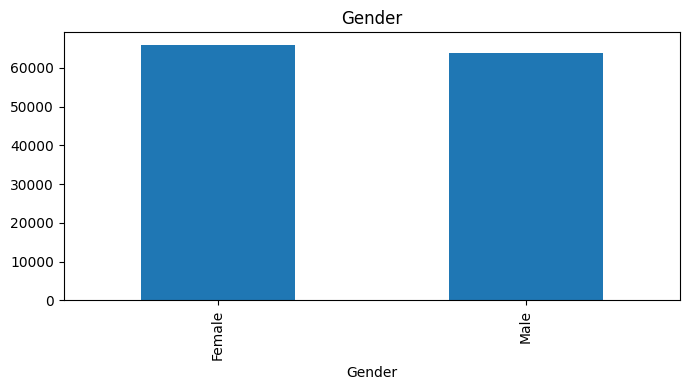

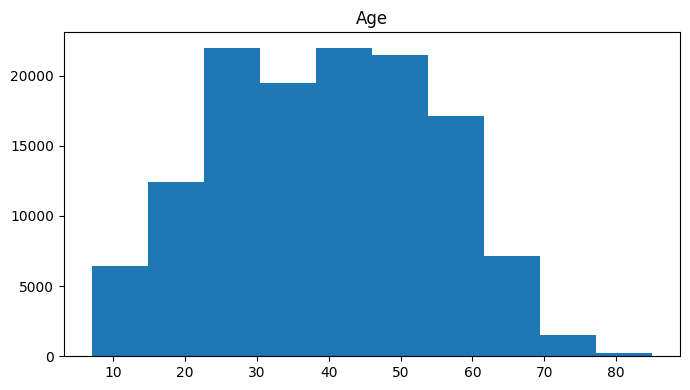

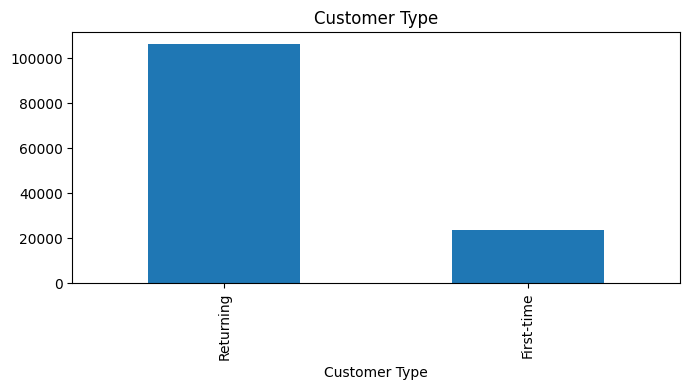

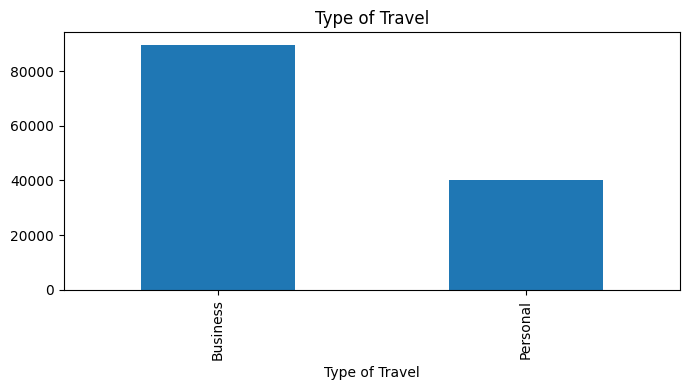

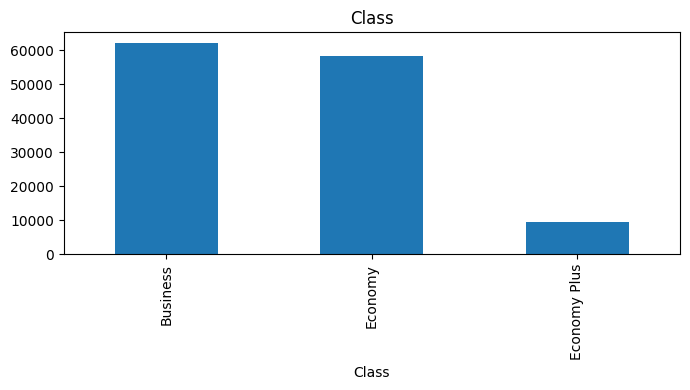

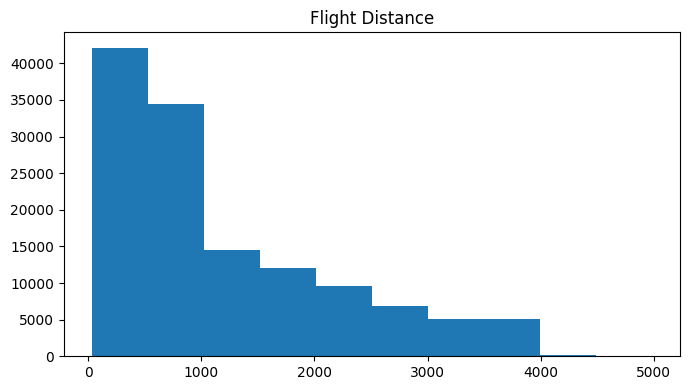

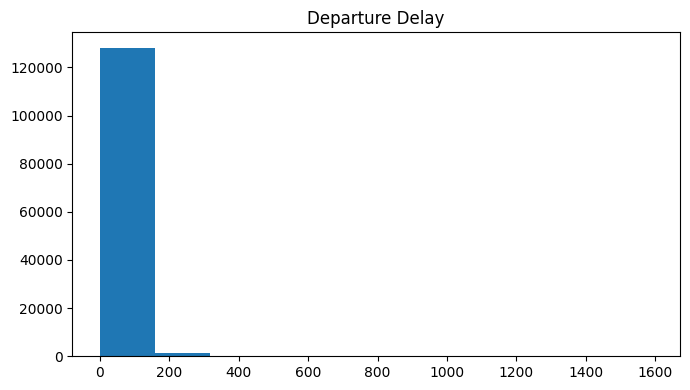

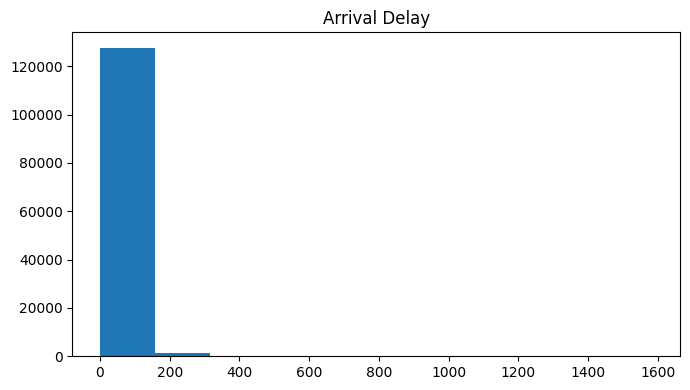

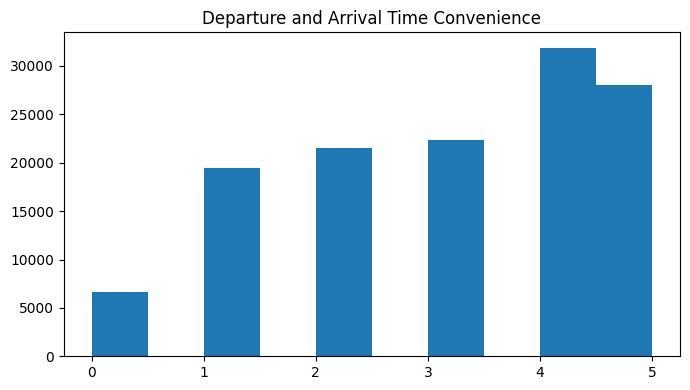

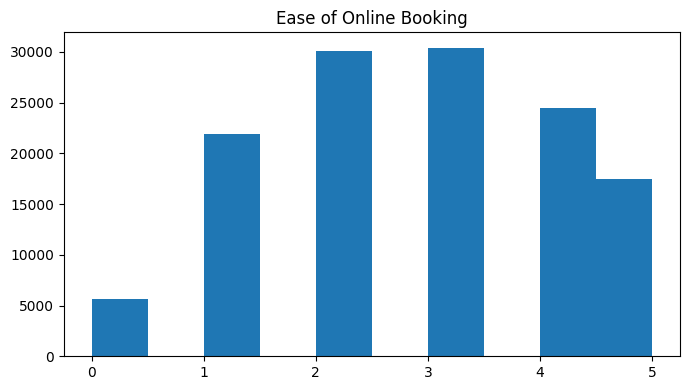

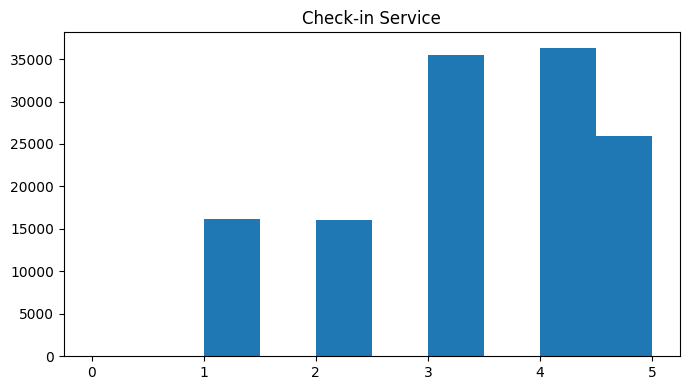

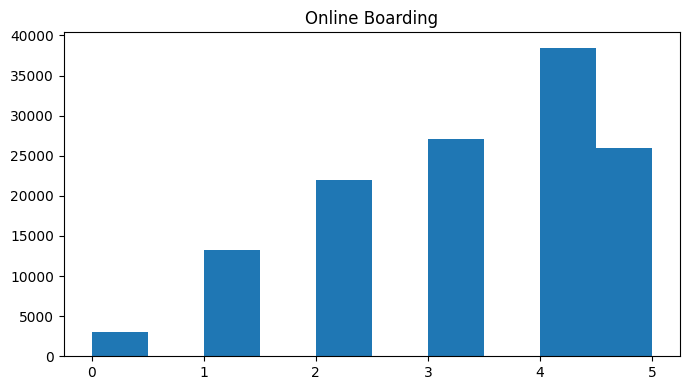

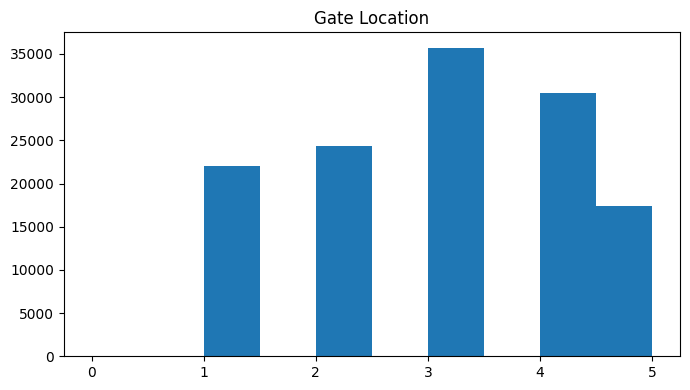

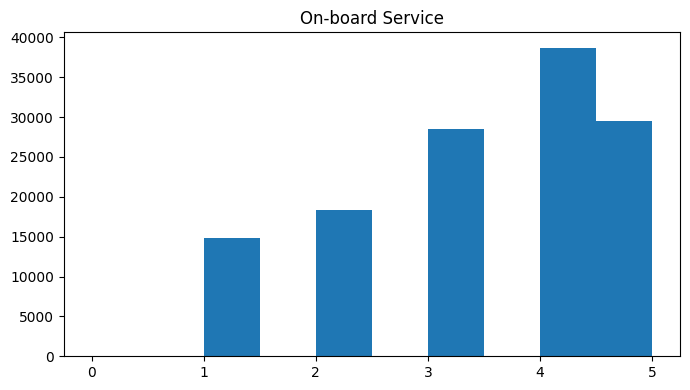

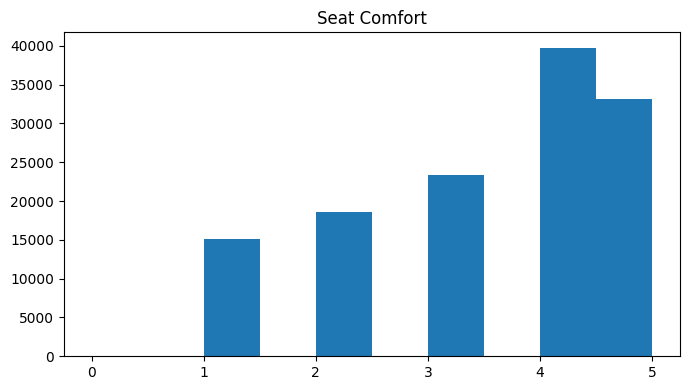

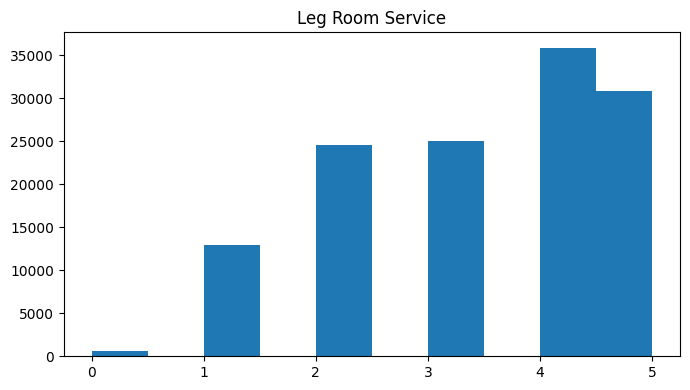

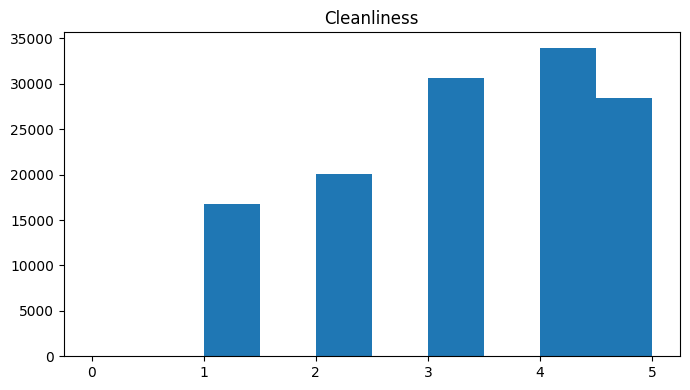

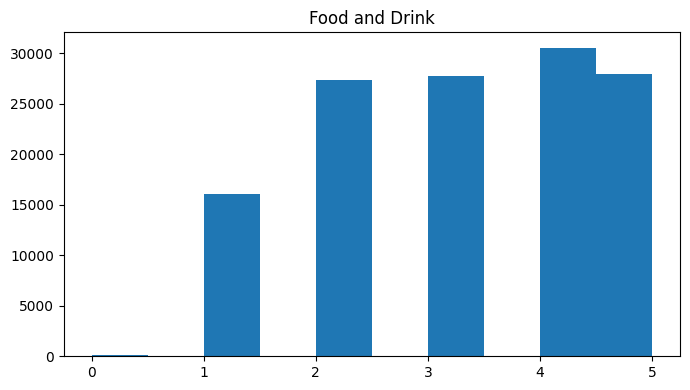

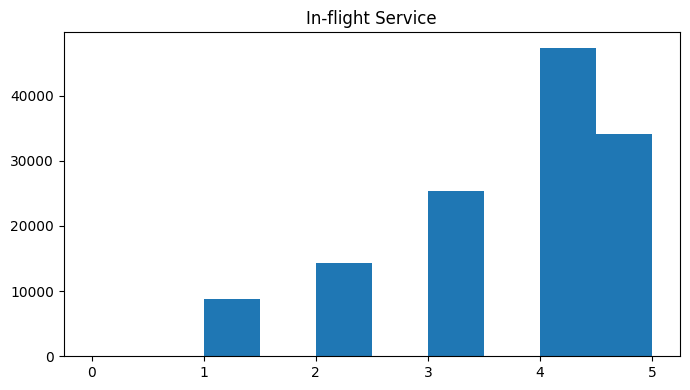

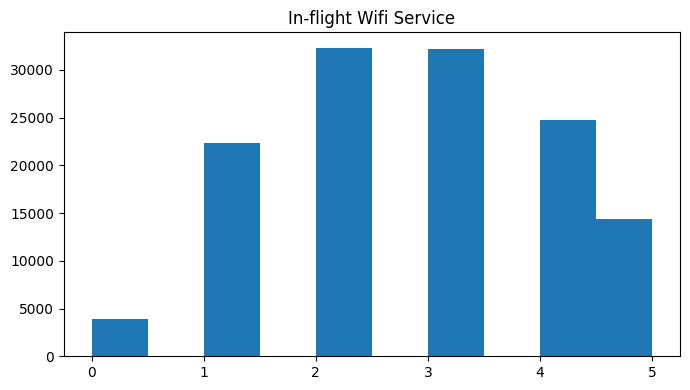

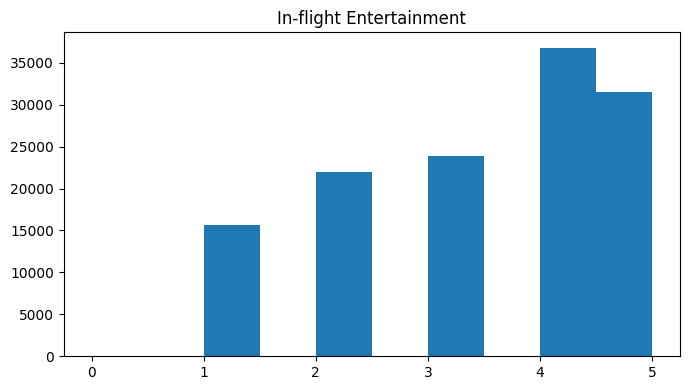

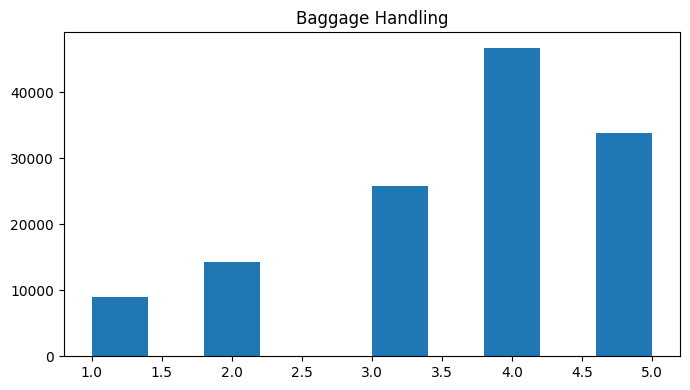

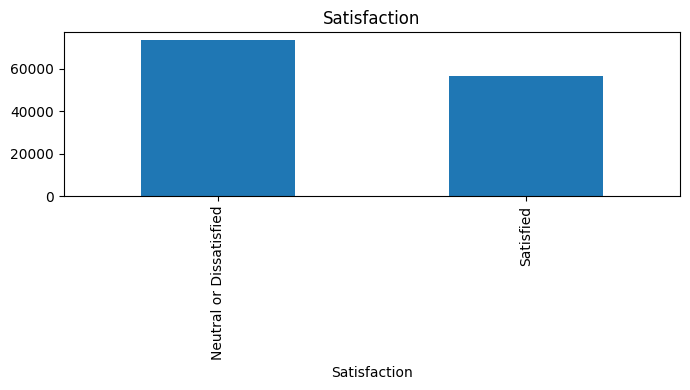

In [5]:
for feature in ps.columns:
    plt.figure(figsize=(7, 4))

    if feature == 'ID':
      continue

    if ps[feature].dtype == 'object' or ps[feature].dtype.name == 'category':
        ps[feature].value_counts().plot(kind='bar')
        plt.title(f'{feature}')

    elif pd.api.types.is_numeric_dtype(ps[feature]):
        plt.hist(ps[feature])
        plt.title(f'{feature}')

    plt.tight_layout()
    plt.show()

It is obvious, in "Class" feature that the class "Economy Plus" is being dominated by the two other classes.

It is obvious that, in "Type of Travel" feature, the class "Business" dominates "Personal"

It is obvious that, in "Customer Type" feature, the class "Returning" dominates "First time"

# (2) Encoding and Filling Missing Values

In [6]:
target_col = 'Satisfaction'
X = ps.drop(columns=target_col)
y = ps[target_col]

X['Arrival Delay'] = X['Arrival Delay'].fillna(X['Arrival Delay'].median())

numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns  # Τις βρίσκω από τώρα για το επόμενο ερώτημα γιατί μετά τη κωδικοποίηση γίνονται και οι κατηγορικές με ακεραίους

X = pd.get_dummies(X, drop_first=True, dtype=int)
y = y.map({'Neutral or Dissatisfied': 0, 'Satisfied': 1})

# (3)

## Normalisation

In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X[numeric_cols] = scaler.fit_transform(X[numeric_cols])

## Convert DataFrame to Numpy arrays

In [8]:
X = X.to_numpy()
y = y.to_numpy()

X.shape, y.shape

((129880, 24), (129880,))

## Split Dataset to Train-Test

In [9]:
from sklearn.model_selection import train_test_split

seed = 0
test_size = 0.3

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=seed)
x_train.shape, y_train.shape, x_test.shape, y_test.shape

((90916, 24), (90916,), (38964, 24), (38964,))

We do normalization to numerical features because there is no logical reason to do it in categorical ones. In order to normalise categorical features, the values would be changed. We can't change the values because each integer is mapped with a category. In theory, these integers are not actual numbers—we write them as numbers just for practical reasons.

## K - NN

### Import Libraries

In [10]:
from math import sqrt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

### Initialise Values

In [11]:
N = x_train.shape[0]
K = [3, 5, 15, 51, 151, int(sqrt(N))]

### Uniform K-NN

In [12]:
print("Uniform K-NN algorithm")

for k in K:
  knn = KNeighborsClassifier(n_neighbors=k, weights='uniform', p=2, metric='minkowski')

  knn.fit(x_train, y_train)

  y_train_pred = knn.predict(x_train)
  train_accuracy = accuracy_score(y_train, y_train_pred)
  train_percentage_accuracy = round(train_accuracy * 100, 2)

  print()

  y_pred = knn.predict(x_test)
  accuracy = accuracy_score(y_test, y_pred)
  accuracy_percentage = round(accuracy*100, 2)

  print(f"Train: K = {k:4d} | Accuracy: {train_percentage_accuracy}%   Test: K = {k:4d} | Accuracy: {accuracy_percentage}%")

Uniform K-NN algorithm

Train: K =    3 | Accuracy: 95.83%   Test: K =    3 | Accuracy: 92.34%

Train: K =    5 | Accuracy: 94.89%   Test: K =    5 | Accuracy: 92.79%

Train: K =   15 | Accuracy: 93.44%   Test: K =   15 | Accuracy: 92.61%

Train: K =   51 | Accuracy: 92.18%   Test: K =   51 | Accuracy: 92.02%

Train: K =  151 | Accuracy: 91.01%   Test: K =  151 | Accuracy: 90.98%

Train: K =  301 | Accuracy: 90.23%   Test: K =  301 | Accuracy: 90.35%


The results say that the best k is 5
There is no overfitting and for large k (i.e. k=301) the algorithm is a bit worse because it looks for a lot of neighbours and loses the actual data.

### Weighted K-NN

In [15]:


print("-----------------------")
print("Weighted K-NN algorithm")

for k in K:
  knn = KNeighborsClassifier(n_neighbors=k, weights='distance', p=2, metric='minkowski')

  knn.fit(x_train, y_train)

  y_train_pred = knn.predict(x_train)
  train_accuracy = accuracy_score(y_train, y_train_pred)
  train_percentage_accuracy = round(train_accuracy * 100, 2)

  y_pred = knn.predict(x_test)
  accuracy = accuracy_score(y_test, y_pred)
  accuracy_percentage = round(accuracy*100, 2)

  print(f"Train: K = {k:4d} | Accuracy: {train_percentage_accuracy}%   Test: K = {k:4d} | Accuracy: {accuracy_percentage}%")

-----------------------
Weighted K-NN algorithm
Train: K =    3 | Accuracy: 100.0%   Test: K =    3 | Accuracy: 92.34%
Train: K =    5 | Accuracy: 100.0%   Test: K =    5 | Accuracy: 92.79%
Train: K =   15 | Accuracy: 100.0%   Test: K =   15 | Accuracy: 92.62%
Train: K =   51 | Accuracy: 100.0%   Test: K =   51 | Accuracy: 92.08%
Train: K =  151 | Accuracy: 100.0%   Test: K =  151 | Accuracy: 91.09%
Train: K =  301 | Accuracy: 100.0%   Test: K =  301 | Accuracy: 90.45%


The results are a bit better than uniform
Here, k = 5 is still the best choice